# Phase 3: Time-Series Forecasting

Forecast **daily revenue** 30 / 60 / 90 days ahead using **ARIMA**, **Prophet**, and a simple **LSTM**.

**Prerequisites:** Phase 1 pipeline complete (`sales_fact` in MySQL).

## 1. Load Data

In [15]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

import importlib

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT / "scripts") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "scripts"))

import forecast_utils
importlib.reload(forecast_utils)

from forecast_utils import (
    FORECAST_DIR,
    HORIZONS,
    HW_PARAMS,
    LSTM_LOOKBACK,
    PROPHET_BACKEND,
    PROPHET_PARAMS,
    SARIMA_ORDER,
    SARIMA_SEASONAL,
    TEST_SIZE,
    VAL_SIZE,
    adf_test,
    best_model_at_horizon,
    forecast_arima,
    forecast_lstm,
    fit_prophet_model,
    plot_seasonal_components,
    forecast_prophet,
    load_daily_series,
    metrics_at_horizons,
    reset_tuning_state,
    rolling_forecast_arima,
    run_all_models,
    save_forecast_outputs,
    time_series_split,
)
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

sns.set_theme(style="whitegrid")

series = load_daily_series()
print(f"Observations: {len(series):,}")
print(f"Range: {series.index.min().date()} to {series.index.max().date()}")
series.tail()

ImportError: cannot import name 'HW_PARAMS' from 'forecast_utils' (d:\E-commerce Sales forecasting\scripts\forecast_utils.py)

## 2. EDA — Trend and Seasonality

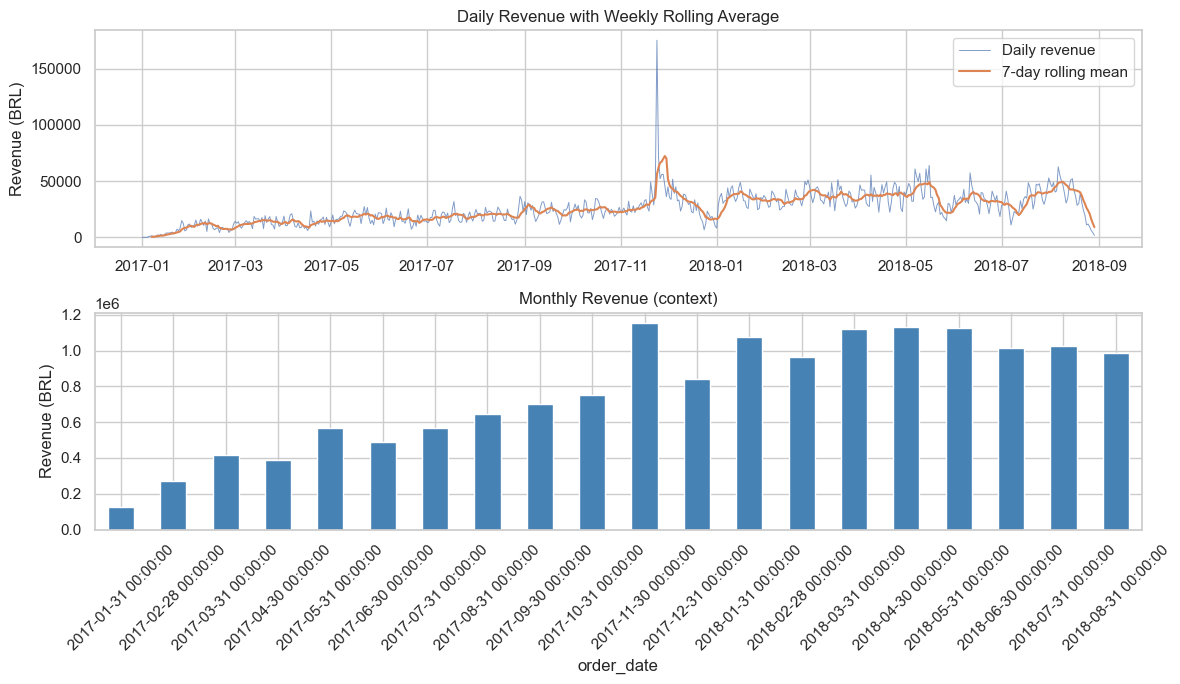

Trend: revenue grows from 2017 into 2018.
Seasonality: weekly patterns visible in rolling mean; November peaks (Black Friday).


In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

axes[0].plot(series.index, series.values, linewidth=0.7, alpha=0.7, label="Daily revenue")
axes[0].plot(series.rolling(7).mean(), linewidth=1.5, label="7-day rolling mean")
axes[0].set_title("Daily Revenue with Weekly Rolling Average")
axes[0].set_ylabel("Revenue (BRL)")
axes[0].legend()

monthly = series.resample("ME").sum()
monthly.plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].set_title("Monthly Revenue (context)")
axes[1].set_ylabel("Revenue (BRL)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Trend: revenue grows from 2017 into 2018.")
print("Seasonality: weekly patterns visible in rolling mean; November peaks (Black Friday).")

## 3. Stationarity (ADF Test)

ARIMA assumes the series (or its differences) has a **stable mean and variance**.

- **p-value < 0.05** → stationary
- Non-stationary raw series → apply differencing (`d=1` in ARIMA)

raw daily revenue: ADF=-3.1949, p=0.0203, stationary=True
first difference: ADF=-7.2167, p=0.0000, stationary=True


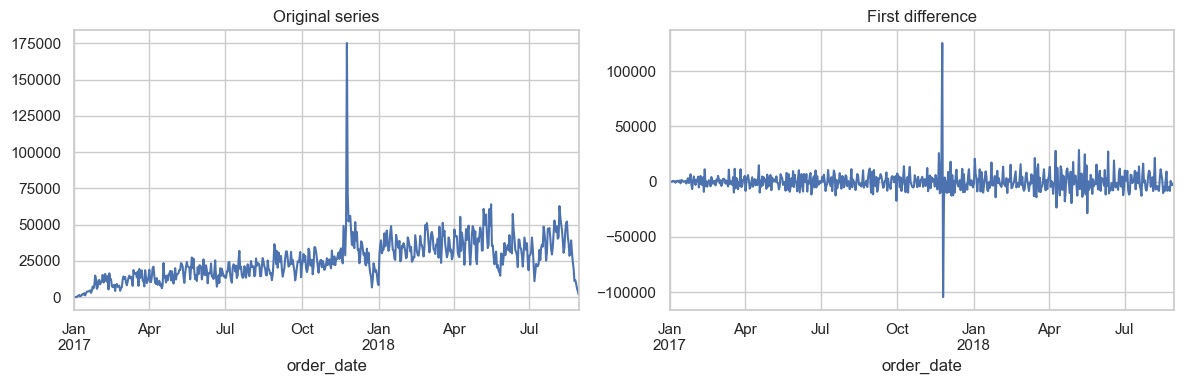

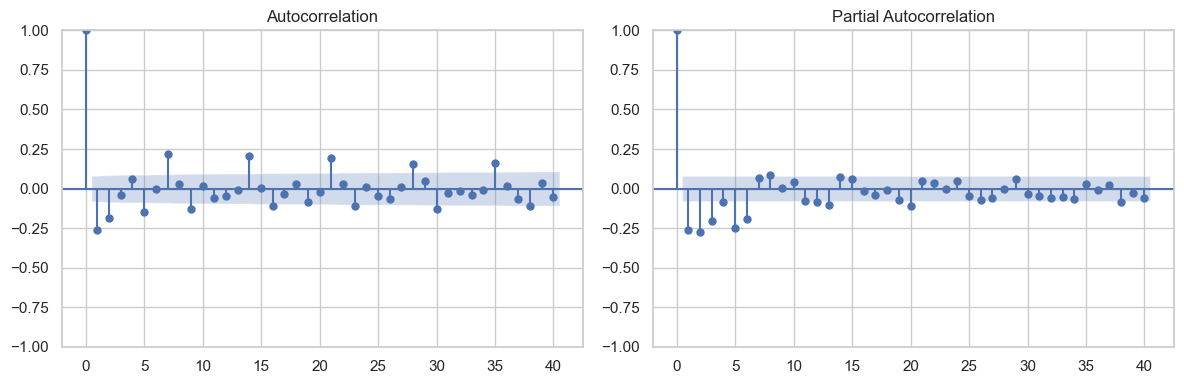

In [ ]:
adf_raw = adf_test(series, "raw daily revenue")
adf_diff = adf_test(series.diff().dropna(), "first difference")

for r in [adf_raw, adf_diff]:
    print(
        f"{r['title']}: ADF={r['adf_statistic']:.4f}, p={r['p_value']:.4f}, "
        f"stationary={r['is_stationary']}"
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
series.plot(ax=axes[0], title="Original series")
series.diff().plot(ax=axes[1], title="First difference")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(series.diff().dropna(), ax=axes[0], lags=40)
plot_pacf(series.diff().dropna(), ax=axes[1], lags=40, method="ywm")
plt.tight_layout()
plt.show()

## 4. Time-Based Train-Test Split

**Never shuffle** time series. Hold out the **last 90 days** for testing.

Train: 516 days (2017-01-01 to 2018-05-31)
Test:  90 days (2018-06-01 to 2018-08-29)


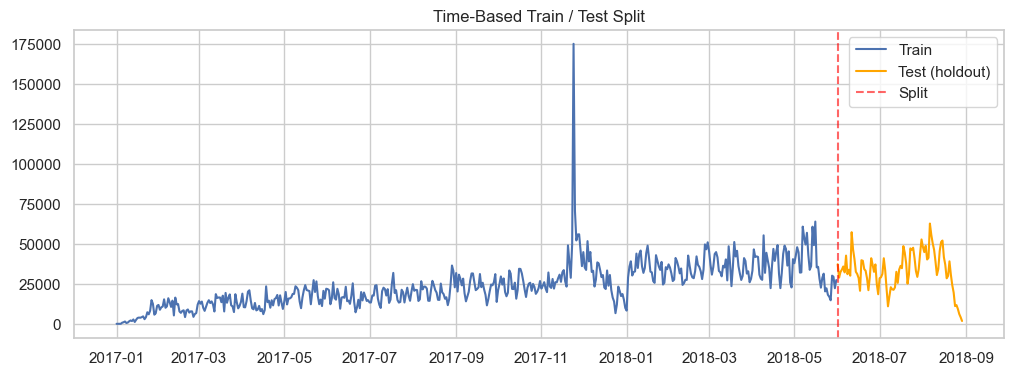

In [ ]:
train, test = time_series_split(series, TEST_SIZE)
print(f"Train: {len(train):,} days ({train.index.min().date()} to {train.index.max().date()})")
print(f"Test:  {len(test):,} days ({test.index.min().date()} to {test.index.max().date()})")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(train.index, train.values, label="Train")
ax.plot(test.index, test.values, label="Test (holdout)", color="orange")
ax.axvline(test.index[0], color="red", linestyle="--", alpha=0.6, label="Split")
ax.set_title("Time-Based Train / Test Split")
ax.legend()
plt.show()

## 5. ARIMA / SARIMA

Hyperparameter tuning: small `(p,d,q) × (P,D,Q,7)` grid scored on the **last 30 train days** (validation). Final model refits on full train and forecasts 90 test days.

,model,horizon,MAE,RMSE,MAPE
0,ARIMA,30,10968.506893,12213.708035,31.563965
1,ARIMA,60,11705.459128,13436.765745,33.443315
2,ARIMA,90,14378.397221,16746.596897,57.335368


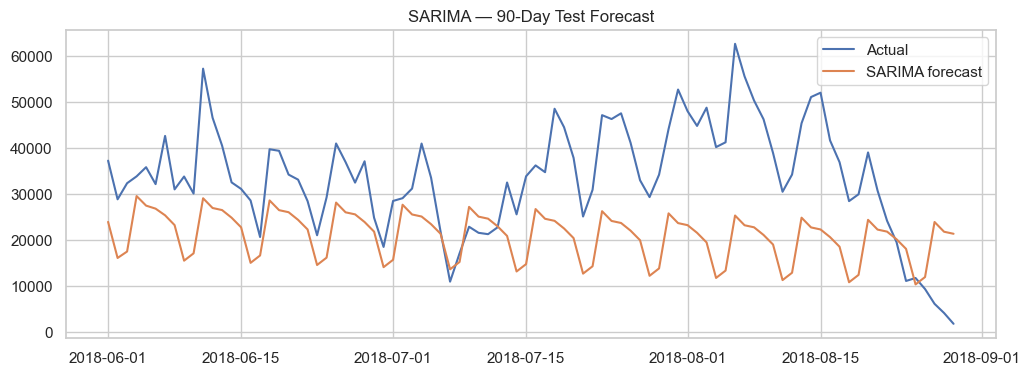

In [ ]:
reset_tuning_state()
arima_pred = forecast_arima(train, steps=TEST_SIZE)
print(f"Selected SARIMA: {SARIMA_ORDER} x {SARIMA_SEASONAL} (val window = {VAL_SIZE} days)")
arima_metrics = metrics_at_horizons(test, arima_pred, model_name="ARIMA")
display(arima_metrics)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(test.index, test.values, label="Actual")
ax.plot(test.index, arima_pred, label="SARIMA forecast")
ax.set_title("SARIMA — 90-Day Test Forecast")
ax.legend()
plt.show()

## 6. Prophet

Tuned on the same 30-day validation window: Prophet prior grid (`changepoint_prior_scale`, `seasonality_prior_scale`) or Holt-Winters fallback (`seasonal`, `damped_trend`) — whichever scores lower validation MAPE.

17:24:03 - cmdstanpy - INFO - Chain [1] start processing
17:24:03 - cmdstanpy - INFO - Chain [1] done processing
17:24:03 - cmdstanpy - ERROR - Chain [1] error: code '3221226105' 
Optimization terminated abnormally. Falling back to Newton.
17:24:03 - cmdstanpy - INFO - Chain [1] start processing
17:24:03 - cmdstanpy - INFO - Chain [1] done processing
17:24:03 - cmdstanpy - ERROR - Chain [1] error: code '3221226105' 
17:24:03 - cmdstanpy - INFO - Chain [1] start processing
17:24:03 - cmdstanpy - INFO - Chain [1] done processing
17:24:03 - cmdstanpy - ERROR - Chain [1] error: code '3221226105' 
Optimization terminated abnormally. Falling back to Newton.
17:24:03 - cmdstanpy - INFO - Chain [1] start processing
17:24:03 - cmdstanpy - INFO - Chain [1] done processing
17:24:03 - cmdstanpy - ERROR - Chain [1] error: code '3221226105' 


Prophet unavailable (RuntimeError); using Holt-Winters fallback.


,model,horizon,MAE,RMSE,MAPE
0,Prophet,30,9704.753945,11221.530568,27.370326
1,Prophet,60,9647.928870,11004.521831,28.311373
2,Prophet,90,11901.790400,13770.153742,63.050804


Prophet Stan backend unavailable — showing statsmodels seasonal decomposition.


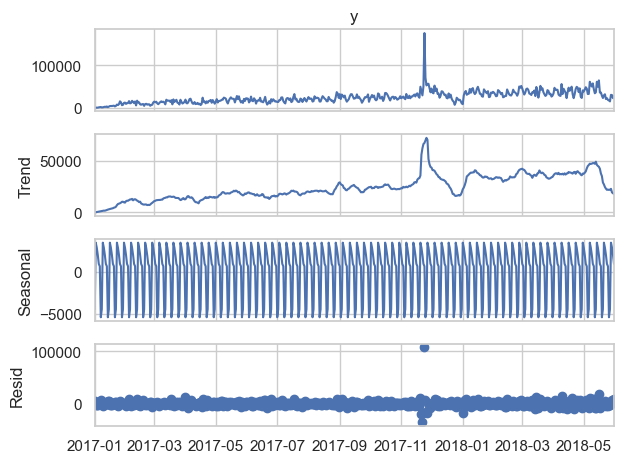

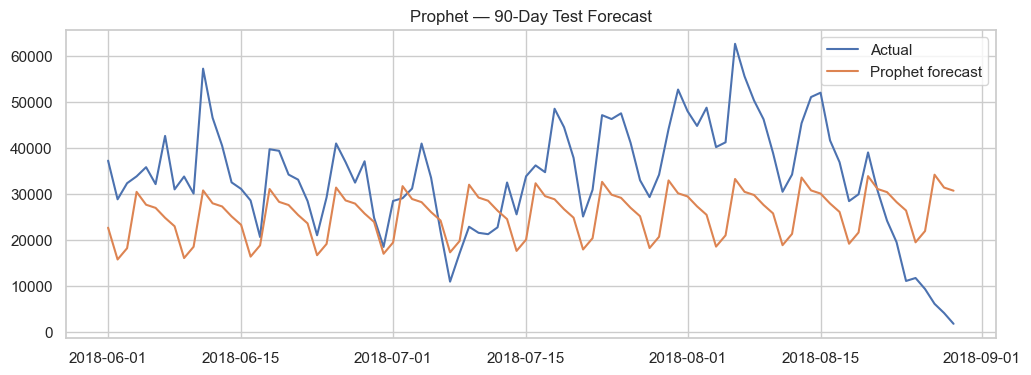

In [ ]:
prophet_model = fit_prophet_model(train)
prophet_pred = forecast_prophet(train, steps=TEST_SIZE)
if PROPHET_BACKEND == "prophet":
    print(f"Selected Prophet params: {PROPHET_PARAMS}")
else:
    print(f"Selected Holt-Winters params: {HW_PARAMS}")
prophet_metrics = metrics_at_horizons(test, prophet_pred, model_name="Prophet")
display(prophet_metrics)

if prophet_model is not None:
    fig = prophet_model.plot_components(
        prophet_model.predict(prophet_model.make_future_dataframe(periods=0))
    )
    plt.show()
else:
    print("Prophet Stan backend unavailable — showing statsmodels seasonal decomposition.")
    plot_seasonal_components(train)
    plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(test.index, test.values, label="Actual")
ax.plot(test.index, prophet_pred, label="Prophet forecast")
ax.set_title("Prophet — 90-Day Test Forecast")
ax.legend()
plt.show()

## 7. LSTM

Tuned LSTM with **day-of-week features**, **7-day direct forecast chunks**, dropout (0.2), and early stopping. Lookback chosen from {28, 35, 42} via validation MAPE — avoids the flat recursive 1-step line.

,model,horizon,MAE,RMSE,MAPE
0,LSTM,30,11125.398294,13036.35050,30.405728
1,LSTM,60,11417.130839,13687.72279,31.926821
2,LSTM,90,13888.858902,16522.53808,56.437378


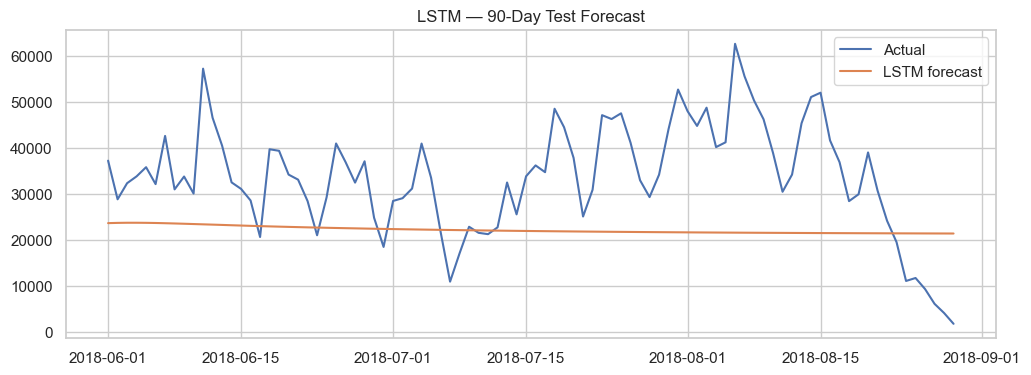

In [ ]:
lstm_pred = forecast_lstm(train, steps=TEST_SIZE)
print(f"Selected LSTM lookback: {LSTM_LOOKBACK} days (7-day chunks, DOW sin/cos features)")
lstm_metrics = metrics_at_horizons(test, lstm_pred, model_name="LSTM")
display(lstm_metrics)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(test.index, test.values, label="Actual")
ax.plot(test.index, lstm_pred, label="LSTM forecast")
ax.set_title("LSTM — 90-Day Test Forecast")
ax.legend()
plt.show()

## 8. Rolling (Walk-Forward) Forecast

Production pattern: refit every 7 days as new actuals arrive (SARIMA demo).

,model,horizon,MAE,RMSE,MAPE
0,ARIMA_rolling,30,6383.457067,7971.230088,19.520499
1,ARIMA_rolling,60,7386.408665,9291.467861,24.725882
2,ARIMA_rolling,90,8501.235273,10874.549295,57.892569


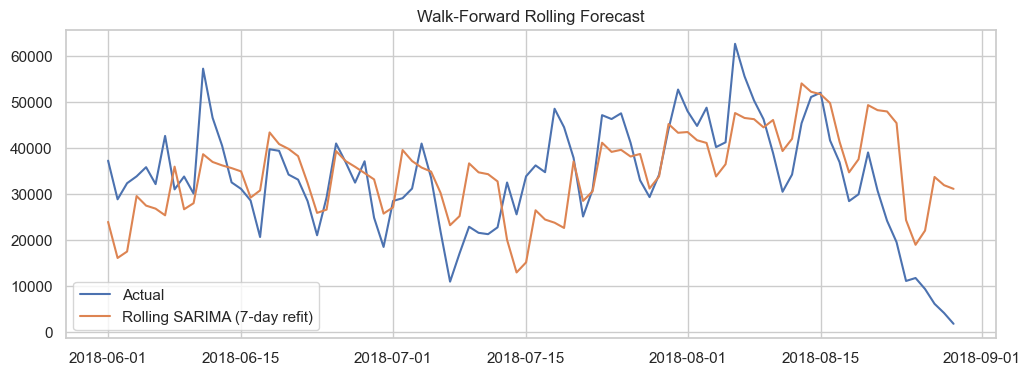

In [ ]:
rolling = rolling_forecast_arima(train, test, step=7)
rolling_metrics = metrics_at_horizons(test, rolling.values, model_name="ARIMA_rolling")
display(rolling_metrics)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(test.index, test.values, label="Actual")
ax.plot(rolling.index, rolling.values, label="Rolling SARIMA (7-day refit)")
ax.set_title("Walk-Forward Rolling Forecast")
ax.legend()
plt.show()

## 9. Model Comparison

| Model | Strengths on Olist data | Weaknesses |
|-------|-------------------------|------------|
| **Prophet** | Trend + weekly/yearly seasonality; handles zeros | Slower; less control than SARIMA |
| **SARIMA** | Explicit weekly seasonality (period=7) | Needs differencing; sensitive to spikes |
| **LSTM** | Can learn non-linear patterns | Needs more data; ~500 train days is small |

Rank by **MAPE** (business %) and **RMSE** (penalizes large errors on spike days like 2017-11-24).

,model,horizon,MAE,RMSE,MAPE
0,ARIMA,30,10968.506893,12213.708035,31.563965
1,ARIMA,60,11705.459128,13436.765745,33.443315
2,ARIMA,90,14378.397221,16746.596897,57.335368
3,Prophet,30,9704.753945,11221.530568,27.370326
4,Prophet,60,9647.928870,11004.521831,28.311373
5,Prophet,90,11901.790400,13770.153742,63.050804
6,LSTM,30,11125.398294,13036.350500,30.405728
7,LSTM,60,11417.130839,13687.722790,31.926821
8,LSTM,90,13888.858902,16522.538080,56.437378


Best model at 90-day horizon (lowest MAPE): LSTM


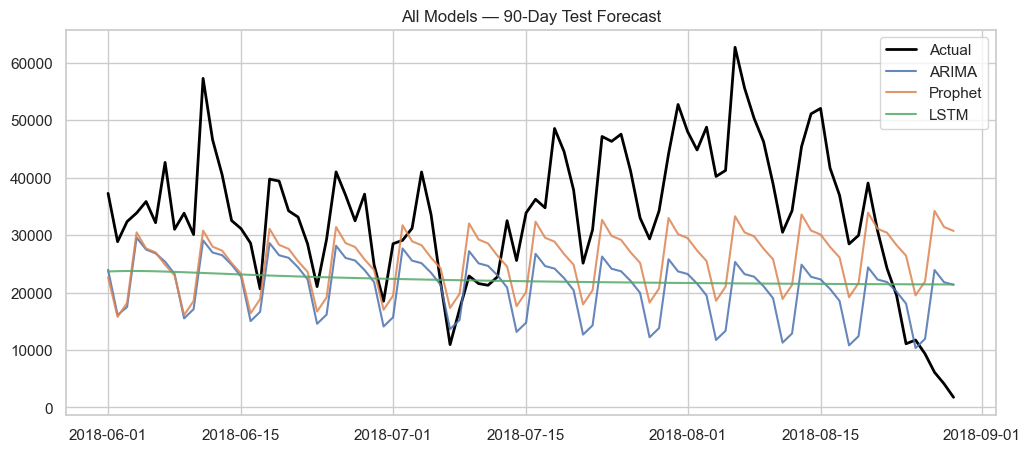

LSTM wins unexpectedly — but often needs more data to generalize reliably.


In [ ]:
forecasts = {"ARIMA": arima_pred, "Prophet": prophet_pred, "LSTM": lstm_pred}
comparison = pd.concat(
    [metrics_at_horizons(test, p, model_name=name) for name, p in forecasts.items()],
    ignore_index=True,
)
display(comparison)

winner = best_model_at_horizon(comparison, horizon=90)
print(f"Best model at 90-day horizon (lowest MAPE): {winner}")

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(test.index, test.values, label="Actual", linewidth=2, color="black")
for name, preds in forecasts.items():
    ax.plot(test.index, preds, label=name, alpha=0.85)
ax.set_title("All Models — 90-Day Test Forecast")
ax.legend()
plt.show()

if winner == "Prophet":
    print("Prophet likely wins: built for business series with multiple seasonalities.")
elif winner == "ARIMA":
    print("SARIMA wins: weekly seasonal structure fits Olist daily sales well.")
else:
    print("LSTM wins unexpectedly — but often needs more data to generalize reliably.")

## 10. Export for Power BI (Phase 4)

In [ ]:
out_dir = save_forecast_outputs(test, forecasts, comparison, train)
print(f"Exported forecasts to {out_dir}")

Exported forecasts to D:\E-commerce Sales forecasting\data\forecasts
